# Clasificación — Infarto de Miocardio

**Minería de datos**  
Prof. Elizabeth Leon Guzman  
Estudiante: David Julian Bustos Cortes · dbustos@unal.edu.co

---

Este notebook corresponde a la entrega final del proyecto. Se aborda la tarea de **clasificación supervisada** para predecir el riesgo de mortalidad (`LET_IS` binarizada: 0 = sobrevive, 1 = fallece por cualquier causa) a partir de las variables clínicas del ingreso hospitalario.

Se evalúan cuatro modelos:
- **Red Neuronal Multicapa (MLP)**
- **Random Forest**
- **Random Forest con MetaCost** (penaliza clasificar como bajo riesgo a un paciente de alto riesgo)
- **Naive Bayes Gaussiano**
- **Clasificador Bayesiano de Red (BernoulliNB + TAN aproximado vía estructura aprendida)**

El dataset es el [Myocardial Infarction Complications Dataset](https://archive.ics.uci.edu/dataset/579/myocardial+infarction+complications) del repositorio UCI: 1700 pacientes con 111 variables clínicas y 12 variables objetivo.

## 1. Instalación de dependencias

In [ ]:
%%capture
!pip install ucimlrepo pgmpy --quiet

## 2. Importaciones

In [ ]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import multiprocessing
from ucimlrepo import fetch_ucirepo

# Preprocesamiento
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler, label_binarize
from sklearn.decomposition import PCA
from sklearn.tree import DecisionTreeClassifier

# Modelos de clasificación
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB, BernoulliNB, CategoricalNB
from pgmpy.models import BayesianNetwork
from pgmpy.estimators import PC, HillClimbSearch, BIC, BDeu
from pgmpy.estimators import MaximumLikelihoodEstimator, BayesianEstimator
from pgmpy.inference import VariableElimination

# Evaluación y validación
from sklearn.model_selection import (
    StratifiedKFold, cross_val_predict, train_test_split,
    GridSearchCV, RepeatedStratifiedKFold, cross_validate
)
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score,
    roc_curve, precision_recall_curve, average_precision_score,
    ConfusionMatrixDisplay, f1_score, recall_score, precision_score
)
from sklearn.pipeline import Pipeline

pd.set_option('display.max_columns', None)

## 3. Carga del dataset

In [ ]:
myocardial_infarction_complications = fetch_ucirepo(id=579)

X_raw = myocardial_infarction_complications.data.features.copy()
target_columns = myocardial_infarction_complications.data.targets.columns.tolist()
y_raw = pd.DataFrame(myocardial_infarction_complications.data.targets, columns=target_columns)

# Definir variables numéricas y categóricas
numeric_cols = [
    "AGE", "S_AD_KBRIG", "D_AD_KBRIG", "S_AD_ORIT", "D_AD_ORIT",
    "K_BLOOD", "NA_BLOOD", "ALT_BLOOD", "AST_BLOOD", "KFK_BLOOD",
    "L_BLOOD", "ROE"
]
categorical_cols = [c for c in X_raw.columns if c not in numeric_cols]

# Corregir tipos
X_raw[numeric_cols] = X_raw[numeric_cols].apply(pd.to_numeric, errors='coerce')
X_raw[categorical_cols] = X_raw[categorical_cols].apply(pd.Categorical)
y_raw = y_raw.apply(pd.Categorical)

data = pd.concat([X_raw, y_raw], axis=1)
print("Shape inicial:", data.shape)
print("Target columns:", target_columns)

Shape inicial: (1700, 123)
Target columns: ['FIBR_PREDS', 'PREDS_TAH', 'JELUD_TAH', 'FIBR_JELUD', 'A_V_BLOK', 'OTEK_LANC', 'RAZRIV', 'DRESSLER', 'ZSN', 'REC_IM', 'P_IM_STEN', 'LET_IS']


## 4. Imputación de datos faltantes

Se aplica la misma estrategia diferenciada de las entregas anteriores:
- **Categóricas**: variables con >30% faltantes se eliminan; las demás se recodifican como `'Missing'`.
- **Numéricas**: mediana para <15%, media + columna indicadora para 15–30%, eliminación para >30%.

Las variables `S_AD_KBRIG` y `D_AD_KBRIG` se eliminan también por alta correlación con `S_AD_ORIT`/`D_AD_ORIT` (documentado en el análisis exploratorio previo).

In [ ]:
# --- Imputación categórica ---
missing_pct_cat = data[categorical_cols].isna().mean()
cat_high_missing = missing_pct_cat[missing_pct_cat > 0.30].index.tolist()
categorical_cols = [c for c in categorical_cols if c not in cat_high_missing]
data = data.drop(columns=cat_high_missing)
print("Categóricas eliminadas (>30% missing):", cat_high_missing)

for col in categorical_cols:
    if 'Missing' not in data[col].cat.categories:
        data[col] = data[col].cat.add_categories('Missing')
    data[col] = data[col].fillna('Missing')

# --- Imputación numérica ---
pct = data[numeric_cols].isna().mean() * 100
low_missing    = pct[pct < 15].index.tolist()
medium_missing = pct[(pct >= 15) & (pct <= 30)].index.tolist()
high_missing   = pct[pct > 30].index.tolist()

print("\nImputación numérica:")
print("  Baja  (<15%):", low_missing)
print("  Media (15-30%):", medium_missing)
print("  Alta  (>30%, eliminadas):", high_missing)

for col in low_missing:
    data[col] = data[col].fillna(data[col].median())

for col in medium_missing:
    ind_col = col + '_missing'
    data[ind_col] = data[col].isna().astype(int).astype('category')
    categorical_cols.append(ind_col)
    data[col] = data[col].fillna(data[col].mean())

data = data.drop(columns=high_missing)
numeric_cols_clean = [c for c in low_missing + medium_missing if c in data.columns]

print(f"\nShape tras imputación: {data.shape}")

Categóricas eliminadas (>30% missing): ['IBS_NASL', 'NA_KB', 'NOT_NA_KB', 'LID_KB']

Imputación numérica:
  Baja  (<15%): ['AGE', 'L_BLOOD', 'ROE']
  Media (15-30%): ['S_AD_ORIT', 'D_AD_ORIT', 'K_BLOOD', 'NA_BLOOD', 'ALT_BLOOD', 'AST_BLOOD']
  Alta  (>30%, eliminadas): ['S_AD_KBRIG', 'D_AD_KBRIG', 'KFK_BLOOD']

Shape tras imputación: (1700, 122)


## 5. Construcción de la variable objetivo

`LET_IS` en el dataset original es multiclase (0 = vivo, 1–7 = distintas causas de muerte). Para clasificación binaria se colapsa en:

- **0**: paciente sobrevive (`LET_IS == 0`)
- **1**: paciente fallece por cualquier causa (`LET_IS ∈ {1,2,3,4,5,6,7}`)

Esto da un problema de **detección de riesgo de mortalidad**, clínicamente relevante y alineado con el clustering previo.

Distribución de clases:
LET_IS
Sobrevive (0)    1429
Fallece (1)       271
Name: count, dtype: int64

Desbalance: 15.9% de mortalidad


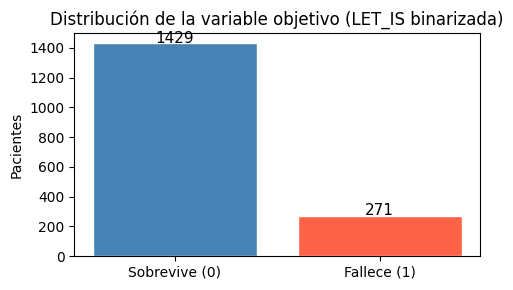

In [ ]:
y_let = pd.to_numeric(data['LET_IS'], errors='coerce').fillna(0).astype(int)
y_bin = (y_let > 0).astype(int)   # 0 = sobrevive, 1 = fallece

print("Distribución de clases:")
print(y_bin.value_counts().rename({0: 'Sobrevive (0)', 1: 'Fallece (1)'}))
print(f"\nDesbalance: {y_bin.mean()*100:.1f}% de mortalidad")

fig, ax = plt.subplots(figsize=(5, 3))
counts = y_bin.value_counts()
ax.bar(['Sobrevive (0)', 'Fallece (1)'], counts.values, color=['steelblue', 'tomato'], edgecolor='white')
for i, v in enumerate(counts.values):
    ax.text(i, v + 5, str(v), ha='center', fontsize=11)
ax.set_ylabel('Pacientes')
ax.set_title('Distribución de la variable objetivo (LET_IS binarizada)')
plt.tight_layout()
plt.show()

## 6. Preparación del conjunto

Se excluyen **todas** las variables objetivo (`target_columns`) del espacio de features para evitar fuga de información.

In [ ]:
# Features: todo excepto targets
feature_cols = [c for c in data.columns if c not in target_columns]
df_feat = data[feature_cols].copy()

# Separar columnas por tipo para el preprocesador
ordinal_cols = [
    "INF_ANAM", "STENOK_AN", "FK_STENOK", "IBS_POST", "GB", "DLIT_AG",
    "ZSN_A", "ant_im", "lat_im", "inf_im", "post_im", "TIME_B_S",
    "R_AB_1_n", "R_AB_2_n", "R_AB_3_n", "NA_R_1_n", "NA_R_2_n", "NA_R_3_n",
    "NOT_NA_1_n", "NOT_NA_2_n", "NOT_NA_3_n"
]
ordinal_cols = [c for c in ordinal_cols if c in df_feat.columns]
nominal_cols = [c for c in categorical_cols if c in df_feat.columns and c not in ordinal_cols]
num_feat_cols = [c for c in numeric_cols_clean if c in df_feat.columns]

print(f"Features totales: {df_feat.shape[1]}")
print(f"  Numéricas: {len(num_feat_cols)}")
print(f"  Ordinales: {len(ordinal_cols)}")
print(f"  Nominales: {len(nominal_cols)}")

Features totales: 110
  Numéricas: 9
  Ordinales: 21
  Nominales: 80


### 6.1 Codificación y normalización

- **Variables numéricas**: `StandardScaler` (media 0, desviación 1).
- **Variables ordinales**: `OrdinalEncoder` (preserva orden natural).
- **Variables nominales**: `OneHotEncoder` (sin orden implícito).

No se aplica discretización previa porque los modelos de clasificación elegidos operan directamente sobre variables continuas (MLP, RF) o pueden manejar datos ya codificados (Naive Bayes).

In [ ]:
# Convertir categóricas a string para los encoders
for col in ordinal_cols + nominal_cols:
    df_feat[col] = df_feat[col].astype(str)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_feat_cols),
        ('ord', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), ordinal_cols),
        ('nom', OneHotEncoder(handle_unknown='ignore', sparse_output=False), nominal_cols),
    ],
    remainder='drop'
)

X = preprocessor.fit_transform(df_feat)
y = y_bin.values

print(f"Shape de X tras preprocesamiento: {X.shape}")
print(f"Shape de y: {y.shape}")

Shape de X tras preprocesamiento: (1700, 263)
Shape de y: (1700,)


### 6.2 Separación de conjunto de entrenamiento y prueba estratificado.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print(f"Train: {X_train.shape[0]} pacientes | Test: {X_test.shape[0]} pacientes")
print(f"Mortalidad en train: {y_train.mean()*100:.1f}% | en test: {y_test.mean()*100:.1f}%")

Train: 1360 pacientes | Test: 340 pacientes
Mortalidad en train: 16.0% | en test: 15.9%


## 7. Modelos de clasificación

Se evalúan cuatro modelos: Red Neuronal Multicapa (MLP), Random Forest, Random Forest con función de costo asimétrica (MetaCost) y Naive Bayes Gaussiano. Para todos, el flujo es el mismo: primero se estima la estabilidad del modelo mediante validación cruzada estratificada de 5 folds sobre el conjunto de entrenamiento, luego se reentrena sobre todo el train con la configuración fija, y finalmente se evalúa sobre el conjunto de test —datos que el modelo nunca vio durante ninguna etapa anterior. Esto permite verificar que los resultados de CV y test sean consistentes, descartando que el rendimiento final sea producto de una partición afortunada del dataset. Para Random Forest, la validación cruzada está embebida en una búsqueda de hiperparámetros por GridSearch, que selecciona la mejor configuración antes de reentrenar.

In [ ]:
CV_TRAIN = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Función de evaluación sobre test
def evaluate_model(name, clf_fitted, X_te, y_te):
    y_pred = clf_fitted.predict(X_te)
    try:
        y_prob = clf_fitted.predict_proba(X_te)[:, 1]
    except AttributeError:
        y_prob = None

    rep = classification_report(y_te, y_pred, target_names=['Sobrevive', 'Fallece'], output_dict=True)
    roc = roc_auc_score(y_te, y_prob) if y_prob is not None else float('nan')
    prc = average_precision_score(y_te, y_prob) if y_prob is not None else float('nan')

    print(f"\n{'='*60}")
    print(f" {name} — Evaluación sobre test")
    print(f"{'='*60}")
    print(classification_report(y_te, y_pred, target_names=['Sobrevive', 'Fallece']))
    print(f"ROC-AUC  : {roc:.4f}")
    print(f"PR-AUC   : {prc:.4f}\n")

    fig, ax = plt.subplots(figsize=(4, 3))
    ConfusionMatrixDisplay(
        confusion_matrix(y_te, y_pred),
        display_labels=['Sobrevive', 'Fallece']
    ).plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(f'Matriz de confusión — {name}')
    plt.tight_layout()
    plt.show()

    return {
        'name'    : name,
        'y_pred'  : y_pred,
        'y_prob'  : y_prob,
        'f1_macro': rep['macro avg']['f1-score'],
        'recall_1': rep['Fallece']['recall'],
        'prec_1'  : rep['Fallece']['precision'],
        'roc_auc' : roc,
        'pr_auc'  : prc,
    }

# Función para reportar cv
def report_cv(name, clf, X_tr, y_tr):
    cv_res = cross_validate(
        clf, X_tr, y_tr,
        cv=CV_TRAIN,
        scoring=['f1_macro', 'roc_auc'],
        return_train_score=False,
        n_jobs=-1
    )
    print(f"\n── CV sobre train — {name}")
    print(f"   F1-macro : {cv_res['test_f1_macro'].mean():.4f} ± {cv_res['test_f1_macro'].std():.4f}")
    print(f"   ROC-AUC  : {cv_res['test_roc_auc'].mean():.4f} ± {cv_res['test_roc_auc'].std():.4f}")

### 7.1 Red Neuronal Multicapa (MLP)

El MLP es un modelo de aprendizaje profundo superficial que aprende representaciones no lineales de las features mediante capas ocultas con activación ReLU. Se usa `class_weight='balanced'` para compensar el desbalance de clases.


── CV sobre train — MLP
   F1-macro : 0.8278 ± 0.0303
   ROC-AUC  : 0.9123 ± 0.0281

 MLP — Evaluación sobre test
              precision    recall  f1-score   support

   Sobrevive       0.91      1.00      0.95       286
     Fallece       1.00      0.48      0.65        54

    accuracy                           0.92       340
   macro avg       0.96      0.74      0.80       340
weighted avg       0.92      0.92      0.91       340

ROC-AUC  : 0.8919
PR-AUC   : 0.7513



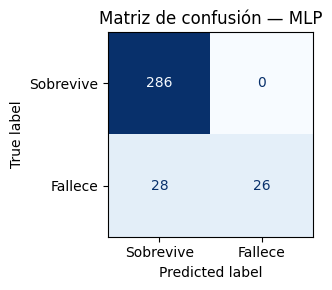

In [ ]:
mlp = MLPClassifier(
    hidden_layer_sizes=(128, 64, 32),
    activation='relu',
    solver='adam',
    alpha=1e-3,
    max_iter=500,
    early_stopping=True,
    validation_fraction=0.1,
    random_state=42,
    learning_rate_init=1e-3,
    batch_size=64,
)

report_cv('MLP', mlp, X_train, y_train)

mlp.fit(X_train, y_train)
res_mlp = evaluate_model('MLP', mlp, X_test, y_test)

El MLP alcanzó un F1-macro de 0.828 ± 0.030 en validación cruzada y 0.80 sobre test, con un ROC-AUC de 0.892 y PR-AUC de 0.751, resultados consistentes con CV que indican buena generalización. El modelo clasifica perfectamente los pacientes que sobreviven (recall=1.00, precisión=0.91), pero es conservador con la clase de mortalidad: detecta solo 26 de 54 pacientes que fallecen (recall=0.48), aunque con precisión perfecta (1.00) —es decir, cuando predice que un paciente fallece, siempre acierta, pero deja pasar la mitad de los casos de alto riesgo.

### 7.2 Random Forest

Random Forest construye un ensemble de árboles de decisión sobre submuestras aleatorias del dataset y subconjuntos de features, reduciendo la varianza mediante promediación. Es robusto al ruido y al desbalance cuando se ajusta `class_weight`. Funciona bien en espacios de alta dimensionalidad sin reducción previa.

Fitting 10 folds for each of 64 candidates, totalling 640 fits

Mejores hiperparámetros : {'criterion': 'entropy', 'max_depth': 7, 'max_features': 11, 'n_estimators': 300}
Mejor F1-macro en CV    : 0.8368

 Random Forest — Evaluación sobre test
              precision    recall  f1-score   support

   Sobrevive       0.92      0.99      0.95       286
     Fallece       0.93      0.52      0.67        54

    accuracy                           0.92       340
   macro avg       0.92      0.76      0.81       340
weighted avg       0.92      0.92      0.91       340

ROC-AUC  : 0.9103
PR-AUC   : 0.7934



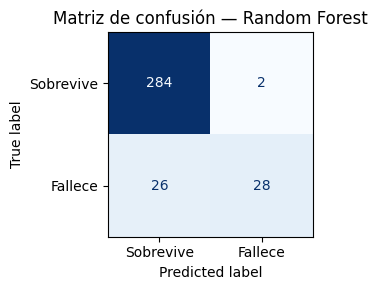

In [ ]:
# La CV está embebida en GridSearchCV — no se llama report_cv por separado.
# refit=True reentrena automáticamente sobre todo X_train con los mejores params.

param_grid = {
    'n_estimators': [150, 300],
    'max_features': [3, 5, 8, 11],
    'max_depth'   : [None, 7, 15, 30],
    'criterion'   : ['gini', 'entropy'],
}

grid_rf = GridSearchCV(
    estimator  = RandomForestClassifier(class_weight='balanced', random_state=42),
    param_grid = param_grid,
    scoring    = 'f1_macro',
    n_jobs     = multiprocessing.cpu_count() - 1,
    cv         = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=42),
    refit      = True,
    verbose    = 1,
    return_train_score=True
)

grid_rf.fit(X_train, y_train)

print(f"\nMejores hiperparámetros : {grid_rf.best_params_}")
print(f"Mejor F1-macro en CV    : {grid_rf.best_score_:.4f}")
res_rf = evaluate_model('Random Forest', grid_rf.best_estimator_, X_test, y_test)

Random Forest, con los hiperparámetros óptimos encontrados por GridSearch (criterion=entropy, max_depth=7, max_features=11, n_estimators=300), alcanzó un F1-macro de 0.837 en CV y 0.81 sobre test, con ROC-AUC de 0.910 y PR-AUC de 0.793 — las mejores métricas discriminativas hasta ahora. Respecto al MLP, el modelo detecta 2 fallecidos adicionales (28 vs 26) a costa de introducir 2 falsos positivos sobre los 286 sobrevivientes, un intercambio clínicamente favorable. Sin embargo, el recall sobre la clase de mortalidad (0.52) sigue siendo el talón de Aquiles —26 pacientes de alto riesgo siguen siendo clasificados como sobrevivientes— lo que confirma que el desbalance de clases no se resuelve únicamente con un modelo más potente, sino que requiere una estrategia explícita de costo asimétrico.

### 7.3 Random Forest con función de costo asimétrica

En contexto clínico el error **falso negativo** —clasificar como bajo riesgo a un paciente que va a fallecer— tiene un costo mucho mayor que el falso positivo. Se reajusta el modelo mediante una **matriz de costos** que penaliza los errores con mayor impacto.

La implementación práctica usa el mismo Random Forest pero con `class_weight` calibrado al costo relativo FN/FP:

$$w_1 = \frac{C_{FN}}{C_{FP}} \cdot \frac{n_0}{n_1}$$

Se usa $C_{FN} = 5$ (clasificar un fallecido como sobreviviente cuesta 5 veces más que el error opuesto).

Peso clase 1 con MetaCost (C_FN=2.5): 13.17

── CV sobre train — RF MetaCost (C_FN=2.5)
   F1-macro : 0.7264 ± 0.0374
   ROC-AUC  : 0.9192 ± 0.0142

 RF MetaCost (C_FN=2.5) — Evaluación sobre test
              precision    recall  f1-score   support

   Sobrevive       0.97      0.69      0.81       286
     Fallece       0.35      0.89      0.51        54

    accuracy                           0.72       340
   macro avg       0.66      0.79      0.66       340
weighted avg       0.87      0.72      0.76       340

ROC-AUC  : 0.9025
PR-AUC   : 0.7819



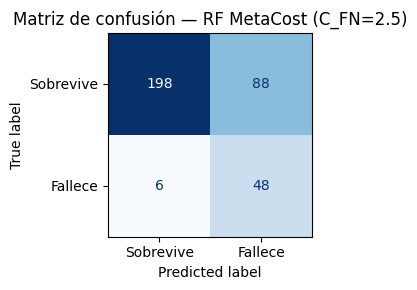

In [ ]:
C_FN = 2.5
C_FP = 1
n0 = (y_train == 0).sum()
n1 = (y_train == 1).sum()
w1_meta = C_FN / C_FP * (n0 / n1)
print(f"Peso clase 1 con MetaCost (C_FN={C_FN}): {w1_meta:.2f}")

best_params = dict(grid_rf.best_params_)
best_params.pop('class_weight', None)

rf_meta = RandomForestClassifier(
    **best_params,
    class_weight={0: 1.0, 1: w1_meta},
    random_state=42
)

report_cv(f'RF MetaCost (C_FN={C_FN})', rf_meta, X_train, y_train)

rf_meta.fit(X_train, y_train)
res_meta = evaluate_model(f'RF MetaCost (C_FN={C_FN})', rf_meta, X_test, y_test)

El RF MetaCost asigna un peso de 13.17 a la clase de mortalidad, equivalente a penalizar cada falso negativo 2.5 veces más que un falso positivo, lo que desplaza explícitamente al modelo hacia la detección de pacientes en riesgo. El efecto es inmediato en la matriz de confusión: los falsos negativos caen de 26 a 6 —el modelo ahora detecta 48 de 54 pacientes que fallecen (recall=0.89)— a costa de un aumento considerable en falsos positivos (88 sobrevivientes clasificados erróneamente como alto riesgo). Este intercambio se refleja en la caída de precisión sobre la clase de mortalidad (0.35) y del F1-macro (0.66), métricas que penalizan los falsos positivos. Sin embargo, en un contexto clínico donde no detectar a un paciente que fallece tiene consecuencias mucho más graves que una alerta innecesaria, este trade-off es deliberado y justificado. El ROC-AUC de 0.903 confirma que la capacidad discriminativa del modelo se mantiene — lo que cambia es el umbral de decisión, no la calidad del ranking.

### 7.4 Naive Bayes Gaussiano

Naive Bayes asume independencia condicional entre features dada la clase. La variante **Gaussiana** modela cada feature numérica con una distribución normal $P(x_i | y) = \mathcal{N}(\mu_{iy}, \sigma_{iy}^2)$. A pesar de su supuesto simplificador, suele funcionar bien como baseline y es muy interpretable. Se aplica sobre el espacio completo pre-procesado.


── CV sobre train — Naive Bayes Gaussiano
   F1-macro : 0.6652 ± 0.1230
   ROC-AUC  : 0.8210 ± 0.0359

 Naive Bayes Gaussiano — Evaluación sobre test
              precision    recall  f1-score   support

   Sobrevive       0.91      0.85      0.88       286
     Fallece       0.42      0.57      0.49        54

    accuracy                           0.81       340
   macro avg       0.67      0.71      0.69       340
weighted avg       0.84      0.81      0.82       340

ROC-AUC  : 0.7753
PR-AUC   : 0.4170



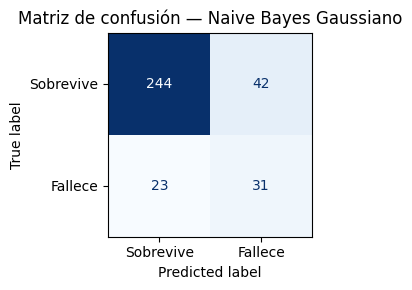

In [ ]:
gnb = GaussianNB(var_smoothing=1e-9)
report_cv('Naive Bayes Gaussiano', gnb, X_train, y_train)

gnb.fit(X_train, y_train)
res_gnb = evaluate_model('Naive Bayes Gaussiano', gnb, X_test, y_test)

Naive Bayes Gaussiano es el modelo más simple y sus resultados lo reflejan: F1-macro de 0.69 sobre test, ROC-AUC de 0.775 y PR-AUC de 0.417 —la más baja del grupo—, con alta variabilidad en CV (±0.123) que indica inestabilidad. El supuesto de independencia condicional entre features no se sostiene en este dataset, donde las correlaciones entre variables clínicas son evidentes. Aun así cumple su rol como baseline probabilístico: su rendimiento inferior confirma que los modelos que capturan dependencias entre variables aportan valor real.

## 8. Comparación global de modelos

Se comparan las métricas clave de los cinco modelos. En un contexto de riesgo clínico:
- **Recall clase 1** es prioritario (detectar pacientes que fallecen).
- **PR-AUC** resume el trade-off precisión/recall en la clase minoritaria.
- **F1-macro** balancea el rendimiento en ambas clases.

In [ ]:
all_results = [res_mlp, res_rf, res_meta, res_gnb]

df_comp = pd.DataFrame([{
    'Modelo'    : r['name'],
    'F1-macro'  : round(r['f1_macro'], 4),
    'Recall-1'  : round(r['recall_1'], 4),
    'Precisión-1': round(r['prec_1'], 4),
    'ROC-AUC'   : round(r['roc_auc'], 4),
    'PR-AUC'    : round(r['pr_auc'], 4),
} for r in all_results])

display(df_comp.set_index('Modelo'))

,F1-macro,Recall-1,Precisión-1,ROC-AUC,PR-AUC
Modelo,,,,,
MLP,0.8017,0.4815,1.0000,0.8919,0.7513
Random Forest,0.8098,0.5185,0.9333,0.9103,0.7934
RF MetaCost (C_FN=2.5),0.6567,0.8889,0.3529,0.9025,0.7819
Naive Bayes Gaussiano,0.6853,0.5741,0.4247,0.7753,0.4170


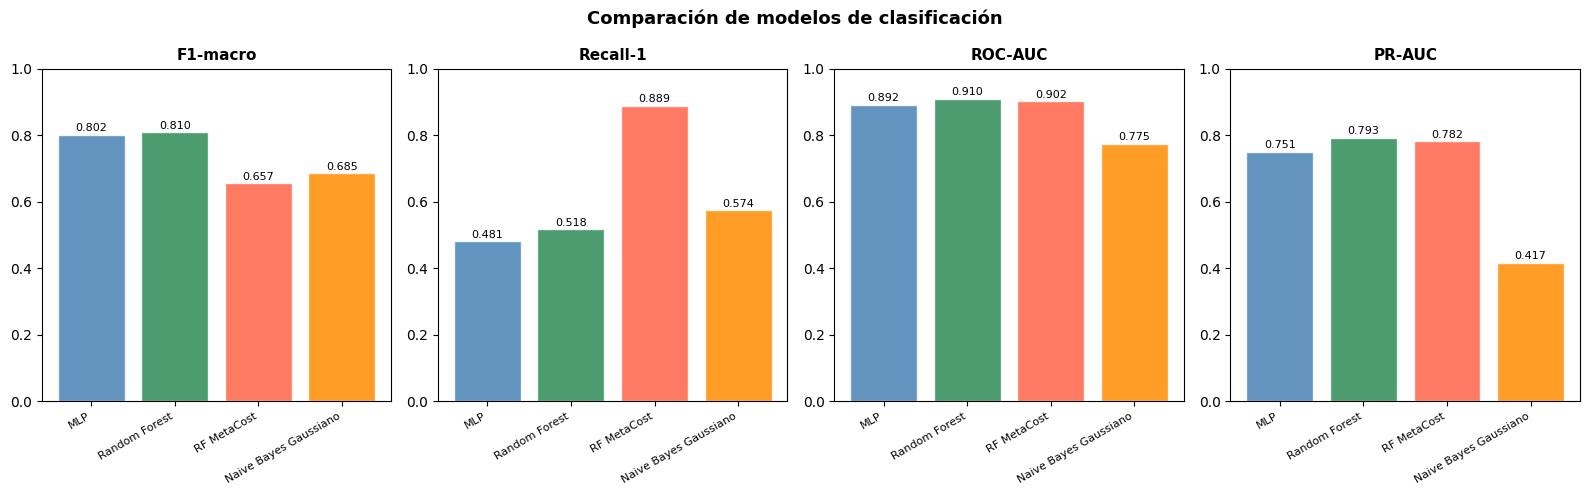

In [ ]:
# Gráfico de barras comparativo
metrics_to_plot = ['F1-macro', 'Recall-1', 'ROC-AUC', 'PR-AUC']
fig, axes = plt.subplots(1, len(metrics_to_plot), figsize=(16, 5))

colors = ['steelblue', 'seagreen', 'tomato', 'darkorange', 'mediumpurple']
models_names = df_comp['Modelo'].tolist()

for ax, metric in zip(axes, metrics_to_plot):
    vals = df_comp[metric].values
    bars = ax.bar(range(len(models_names)), vals, color=colors, edgecolor='white', alpha=0.85)
    ax.set_xticks(range(len(models_names)))
    ax.set_xticklabels([m.split('(')[0].strip() for m in models_names],
                        rotation=30, ha='right', fontsize=8)
    ax.set_title(metric, fontsize=11, fontweight='bold')
    ax.set_ylim(0, 1.0)
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                f'{v:.3f}', ha='center', fontsize=8)

plt.suptitle('Comparación de modelos de clasificación', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

### 8.1 Matrices de confusión

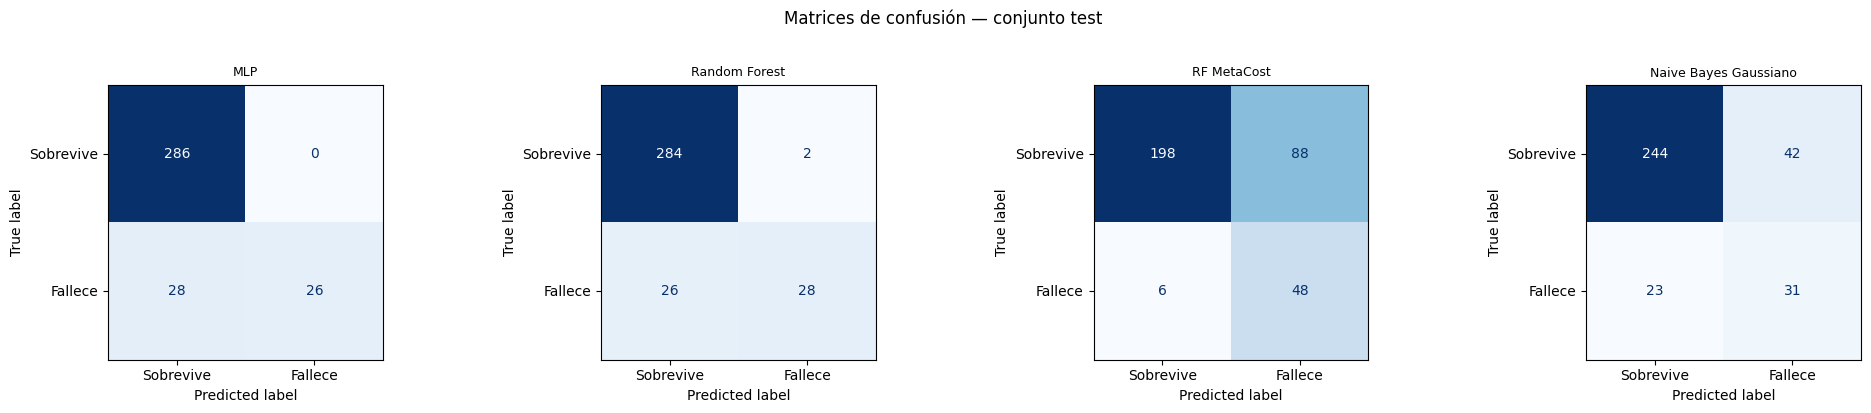

In [ ]:
fig, axes = plt.subplots(1, len(all_results), figsize=(20, 4))

for ax, res in zip(axes, all_results):
    cm = confusion_matrix(y_test, res['y_pred'])
    disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                                   display_labels=['Sobrevive', 'Fallece'])
    disp.plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(res['name'].split('(')[0].strip(), fontsize=9)

plt.suptitle('Matrices de confusión — conjunto test', y=1.02)
plt.tight_layout()
plt.show()

### 8.2 Curvas ROC y Precisión-Recall

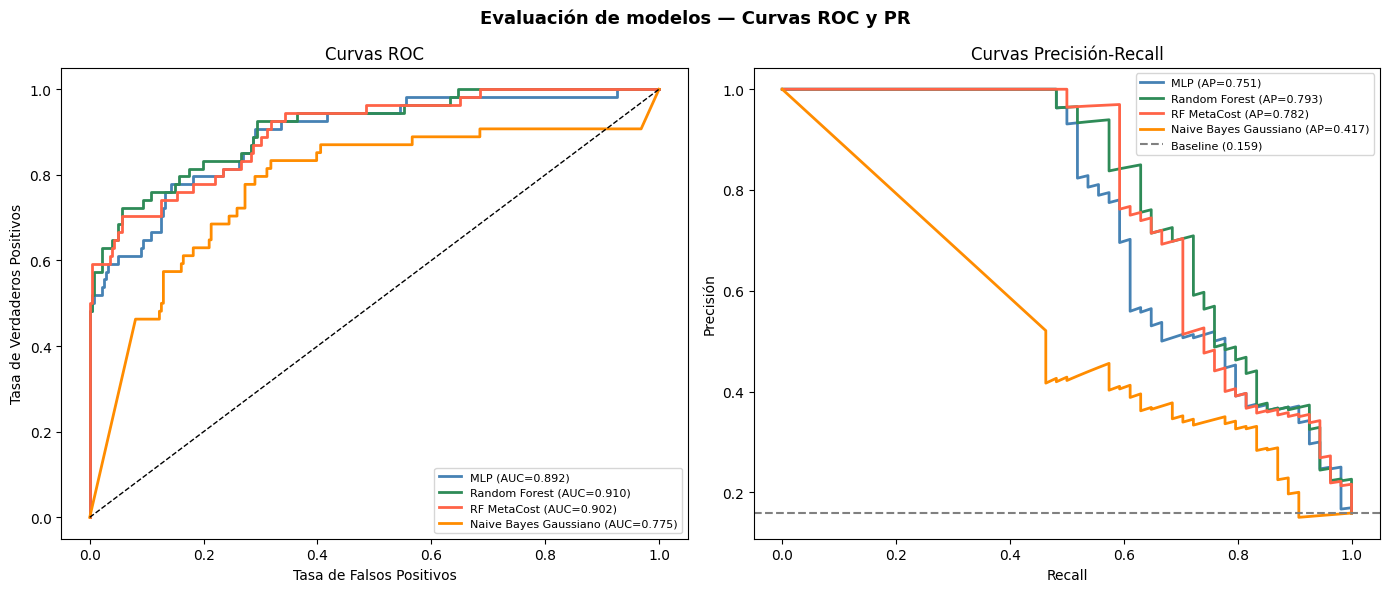

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

for res, color in zip(all_results, colors):
    if res['y_prob'] is None:
        continue
    label_short = res['name'].split('(')[0].strip()

    # ROC
    fpr, tpr, _ = roc_curve(y_test, res['y_prob'])
    ax1.plot(fpr, tpr, color=color, linewidth=2,
             label=f"{label_short} (AUC={res['roc_auc']:.3f})")

    # PR
    prec, rec, _ = precision_recall_curve(y_test, res['y_prob'])
    ax2.plot(rec, prec, color=color, linewidth=2,
             label=f"{label_short} (AP={res['pr_auc']:.3f})")

# ROC
ax1.plot([0,1],[0,1],'k--',linewidth=1)
ax1.set_xlabel('Tasa de Falsos Positivos')
ax1.set_ylabel('Tasa de Verdaderos Positivos')
ax1.set_title('Curvas ROC')
ax1.legend(fontsize=8)

# PR
baseline = y_test.mean()
ax2.axhline(baseline, ls='--', color='gray', label=f'Baseline ({baseline:.3f})')
ax2.set_xlabel('Recall')
ax2.set_ylabel('Precisión')
ax2.set_title('Curvas Precisión-Recall')
ax2.legend(fontsize=8)

plt.suptitle('Evaluación de modelos — Curvas ROC y PR', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## 9. Conclusiones


Los cuatro modelos evaluados confirman que el problema de predicción de mortalidad en infarto de miocardio es tratable con buena capacidad discriminativa: MLP, Random Forest y RF MetaCost superan ROC-AUC de 0.89, muy por encima del baseline (0.159 en PR), lo que indica que las variables clínicas del ingreso hospitalario contienen señal predictiva real. Naive Bayes queda rezagado en todas las métricas, especialmente en PR-AUC (0.417), evidenciando que el supuesto de independencia condicional no es válido en este dominio.

La curva ROC muestra que MLP, RF y MetaCost son prácticamente indistinguibles en capacidad de ranking — la diferencia está en el umbral de decisión, no en la calidad del modelo subyacente. La curva PR, más informativa bajo desbalance, separa mejor los modelos: Random Forest (0.793) y MetaCost (0.782) dominan sobre MLP (0.751) y especialmente sobre Naive Bayes (0.417).

La elección del modelo final depende del objetivo clínico. Random Forest es el modelo más equilibrado (F1-macro=0.810, ROC-AUC=0.910) y el recomendado si se busca rendimiento general. RF MetaCost es el modelo indicado cuando el costo de un falso negativo es inaceptable: detecta 48 de 54 fallecidos (recall=0.889) a costa de 88 falsas alarmas — un intercambio que en un entorno hospitalario real es preferible a dejar pasar pacientes en riesgo crítico.